In [3]:
from pathlib import Path
import pandas as pd

In [4]:
FILENAME = Path("../data/dummy_experiment.csv")

In [ ]:
# def tweak_dataframe(df):

#     return (df
#             .rename(columns={"Participant ID": "id",
#                              "Gender": "gender",
#                              "Country of Origin": "country",
#                              "Cohort": "cohort",
#                              "Condition": "condition",
#                              "Juggling time": "juggling_time",
#                              "Max pineapples": "max_pineapples"
#                              })
#             .replace({"gender": {"M": "male", "F": "female", "m": "male", "f": "female", "male ": "male"},
#                       "country": {"England": "UK"},
#                       "cohort": {"first": 1, "second": 2, "third": 3}})
#             .assign(juggling_time=lambda x: x.juggling_time.str.replace(" seconds", ""))
#             .astype({"juggling_time": "int16",
#                      "gender": "category",
#                      "country": "category",
#                      "cohort": "category",
#                      "condition": "category",
#                      "max_pineapples": "int16"})
#             .query("id < 9000")
            
#     )

# df = pd.read_csv(FILENAME, sep=";")

# df = tweak_dataframe(df)

In [69]:
df.juggling_time.unique()

array([115,  85,  98, 101,  32,  80, 159,  69,  35,  67,  48,  49, 102,
         7,  33, 104,  93,  82,  56,  68,  62, 178,  78,  50,  22, 142,
        13, 129, 158,  87,  73, 116, 151,  64,   9,  92,  99, 117, 114,
       123,  79,  83, 141,  60, 119,   4,  94,  89,  42, 175, 110,   0,
       125,  90, 180, 122,  61,  51, 108, 103, 100,  88, 164,  15, 132,
        45, 111, 140,  11,  46, 128, 169,  43,  70, 167,  58,  97,  25,
        65,  84, 149, 109, 174, 148, 113, 154,  24,  77,   3,  75,  39,
       166,  57, 160,   5,  27, 163, 126, 118, 120, 146, 171,  74, 143,
         2, 176, 177,  91,  16,   1,  66, 165, 161,  72, 138,  81, 106,
       135,  63, 136,  28,   8, 147, 133,  41, 157,  95,  96,  53, 107,
       130,  31, 134, 168, 172,  71, 150,  26,  18,  34,  52,  76, 105,
        44, 131, 127,  12, 170, 144,  86,  14,  20, 145,   6,  36,  55,
       173, 152, 155,  29,  17,  37, 137,  21, 153,  19,  54, 121, 162,
        30,  10, 112,  23,  47,  59, 156, 139, 124, 179,  40,  3

In [70]:
df

,id,gender,country,cohort,condition,juggling_time,max_pineapples
7,1517,female,Sweden,2,dcaf,115,2
8,1332,male,UK,2,dcaf,85,4
9,1813,female,UK,2,dcaf,98,6
10,1359,male,UK,3,dcaf,98,4
11,1757,male,UK,1,caf,101,3
...,...,...,...,...,...,...,...
1595,1563,female,Finland,1,dcaf,40,1
1596,1518,male,USA,1,dcaf,25,2
1597,1051,female,Sweden,3,dcaf,53,3
1598,1228,male,UK,1,dcaf,51,3


In [65]:
df.dtypes

id                   int64
gender            category
country           category
cohort            category
condition         category
juggling_time        int16
max_pineapples       int16
dtype: object

In [66]:
df.memory_usage(deep=True)

Index               132
id                12800
gender             1724
country            1972
cohort             1624
condition          1721
juggling_time      3200
max_pineapples     3200
dtype: int64

In [73]:
mem = df.memory_usage(deep=True).sum() / 1000000

print(f"Memory usage of dataframe is {mem:.2f} MB")

Memory usage of dataframe is 0.03 MB


<Axes: xlabel='juggling_time', ylabel='max_pineapples'>

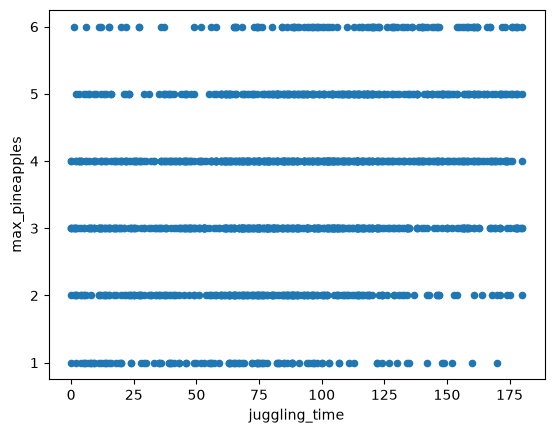

In [ ]:
import matplotlib.pyplot as plt

df.plot(kind="scatter", x="juggling_time", y="max_pineapples")



<Axes: title={'center': 'max_pineapples'}, xlabel='country'>

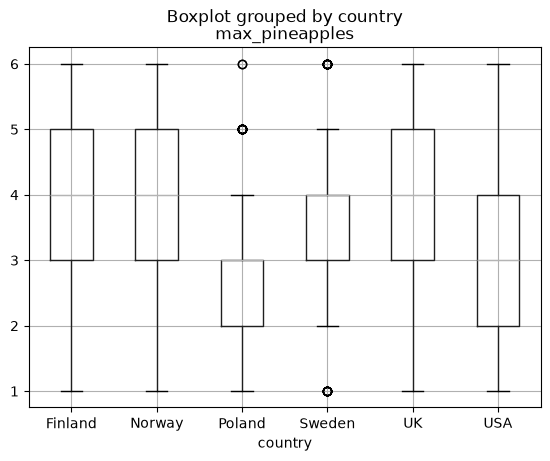

In [79]:
df.boxplot(column="max_pineapples", by="country")

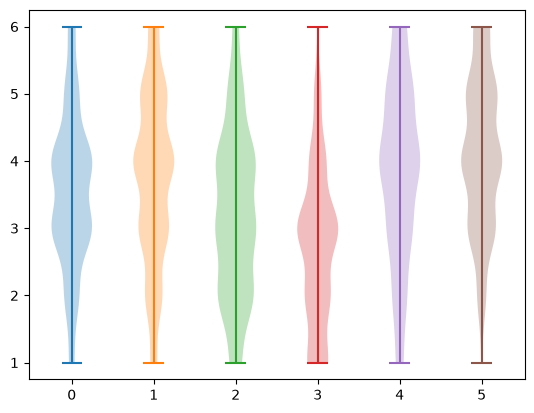

In [84]:
f, ax = plt.subplots()

for idx, country in enumerate(df.country.unique()):

    ax.violinplot(df.query("country == @country").max_pineapples, positions=[idx])
